# ConvLSTM next-composite NDVI forecasting — Vaijapur tehsil (corrected protocol)

This notebook replaces `ConvLSTM-spatio_tempo_forecasting_NDVI_MODIS_with_dropout.ipynb`. It fixes the
issues found in the integrity check of the manuscript:

| Issue in the original run | What this notebook does |
|---|---|
| Test set used as `validation_data` | Separate chronological **train / validation / test** split (70 / 10 / 20 % of windows). The test set is used **once**, for the final scores. |
| Min–max scaling over all frames | Scaling constants come from the **training frames only**. |
| No QA masking; gap filling used future frames; undocumented 3×3 smoothing | Expects a QA-masked stack (see `gee_export_mod13q1_vaijapur.js`). Gaps are filled **causally** (last valid past value). **No spatial smoothing.** Metrics use only QA-valid target pixels. |
| Metrics on scaled values; SSIM from one frame | All metrics in **NDVI units** on valid pixels; SSIM is the **mean over all test frames**. |
| No baselines, single run | **Persistence, seasonal-naïve, per-pixel climatology and a CNN** on the same test targets; ConvLSTM and CNN over **5 seeds** (mean ± SD); **95 % block-bootstrap CIs** and skill vs persistence. |
| Table 5 mixed two runs; wrong dates | Every number and figure comes from this one run. Figures are labelled with the **real composite dates**. `results/results_summary.md` contains text and tables ready to paste. |

**Runtime:** Colab → *Runtime ▸ Change runtime type ▸ T4 GPU*. Upload `ndvi_stack.tif` and `NDVI_Timestamps.csv` (from the GEE script) to `/content`, or mount Drive and change the paths below. Then *Runtime ▸ Run all*.

In [1]:
# Colab already has TensorFlow, scikit-image, pandas and matplotlib.
!pip -q install rasterio

## 1. Configuration

In [4]:
import os, json, math, platform, warnings, datetime as dt
warnings.filterwarnings('ignore', message='Mean of empty slice')
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import rasterio
import scipy
import skimage
from scipy.stats import pearsonr
from skimage.metrics import structural_similarity
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# ---- paths ----
STACK_PATH = 'ndvi_stack.tif'          # one band per composite (from the GEE script)
DATES_PATH = 'NDVI_Timestamps.csv'     # column "date", one row per band
OUT_DIR    = 'results'

# ---- protocol ----
SEQ_LEN    = 5        # input composites per window
TEST_FRAC  = 0.20     # final 20 % of windows -> test (used once)
VAL_FRAC   = 0.10     # previous 10 % -> validation (early stopping, model choice)
SEASON     = 23       # composites per year (seasonal-naive lag)
SEEDS      = [0, 1, 2, 3, 4]
MAX_EPOCHS = 50
PATIENCE   = 8        # early stopping on validation loss
MIN_EPOCHS = 5        # early stopping cannot trigger before this epoch
BN_MOMENTUM = 0.9     # Keras default 0.99 adapts too slowly with ~45 steps/epoch
BATCH      = 4
LR         = 1e-3

# ---- evaluation ----
N_BOOT     = 1000     # bootstrap resamples
BLOCK      = 4        # block length in composites (~2 months) for the block bootstrap
EXAMPLE_TARGET_DATE = '2024-03-21'     # frame shown in Figs 4 and 8 (must be a test date)

# ---- data cleaning ----
FILL_VALUES = [-9999, -3000]           # GEE unmask value; raw MODIS fill value
VALID_RANGE = (-0.2, 1.0)              # NDVI outside this range treated as missing

os.makedirs(OUT_DIR, exist_ok=True)
print('TensorFlow', tf.__version__, '| GPUs:', tf.config.list_physical_devices('GPU'))

TensorFlow 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Load the stack and check it

{
  "n_composites": 253,
  "height_px": 19,
  "width_px": 23,
  "crs": "PROJCS[\"MODIS Sinusoidal\",GEOGCS[\"WGS 84\",DATUM[\"WGS_1984\",SPHEROID[\"WGS 84\",6378137,298.257223563,AUTHORITY[\"EPSG\",\"7030\"]],AUTHORITY[\"EPSG\",\"6326\"]],PRIMEM[\"Greenwich\",0],UNIT[\"degree\",0.0174532925199433,AUTHORITY[\"EPSG\",\"9122\"]]],PROJECTION[\"Sinusoidal\"],PARAMETER[\"longitude_of_center\",0],PARAMETER[\"false_easting\",0],PARAMETER[\"false_northing\",0],UNIT[\"metre\",1,AUTHORITY[\"EPSG\",\"9001\"]],AXIS[\"Easting\",EAST],AXIS[\"Northing\",NORTH]]",
  "pixel_size_m": [
    250.0,
    250.0
  ],
  "extent_km": [
    5.75,
    4.75
  ],
  "first_date": "2014-01-01",
  "last_date": "2024-12-18",
  "missing_composites_in_series": 0,
  "valid_pixel_fraction_overall": 0.9999,
  "scale_note": "already in NDVI units"
}


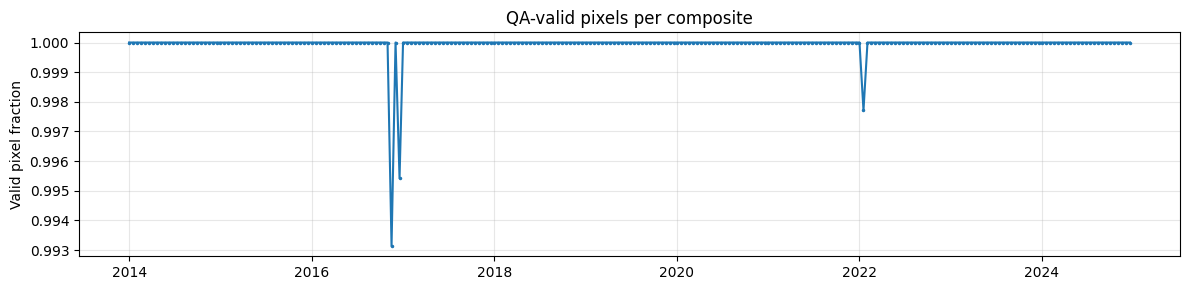

In [5]:
with rasterio.open(STACK_PATH) as src:
    raw = src.read().astype('float64')
    crs, res, nodata, bounds = src.crs, src.res, src.nodata, src.bounds

dates = pd.to_datetime(pd.read_csv(DATES_PATH)['date']).reset_index(drop=True)
T, H, W = raw.shape
assert len(dates) == T, f'{T} bands but {len(dates)} dates'
assert dates.is_monotonic_increasing

for fv in FILL_VALUES + ([nodata] if nodata is not None else []):
    raw[raw == fv] = np.nan
scale_note = 'already in NDVI units'
if np.nanmax(raw) > 1.5:                    # raw integer NDVI (x10000)
    raw *= 0.0001
    scale_note = 'MODIS scale factor 0.0001 applied'
raw[(raw < VALID_RANGE[0]) | (raw > VALID_RANGE[1])] = np.nan

# pixel size in metres
if crs is not None and crs.is_geographic:
    lat_c = (bounds.top + bounds.bottom) / 2
    px_x_m = res[0] * 111320 * math.cos(math.radians(lat_c))
    px_y_m = res[1] * 110574
else:
    px_x_m, px_y_m = res

gaps = dates.diff().dt.days.dropna()
missing_composites = int(((gaps / 16).round() - 1).clip(lower=0).sum())   # e.g. a 32-day gap = 1 missing composite
valid = ~np.isnan(raw)

data_summary = {
    'n_composites': int(T), 'height_px': int(H), 'width_px': int(W),
    'crs': str(crs), 'pixel_size_m': [round(float(px_x_m), 1), round(float(px_y_m), 1)],
    'extent_km': [round(W * px_x_m / 1000, 2), round(H * px_y_m / 1000, 2)],
    'first_date': str(dates.iloc[0].date()), 'last_date': str(dates.iloc[-1].date()),
    'missing_composites_in_series': missing_composites,
    'valid_pixel_fraction_overall': round(float(valid.mean()), 4),
    'scale_note': scale_note,
}
json.dump(data_summary, open(f'{OUT_DIR}/data_summary.json', 'w'), indent=2)
print(json.dumps(data_summary, indent=2))

plt.figure(figsize=(12, 3))
plt.plot(dates, valid.reshape(T, -1).mean(1), '.-', ms=3)
plt.ylabel('Valid pixel fraction'); plt.title('QA-valid pixels per composite'); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/valid_fraction.png', dpi=200); plt.show()

## 3. Windows and chronological train / validation / test split

In [6]:
L = SEQ_LEN
N = T - L                                   # number of windows
target_idx = np.arange(L, T)                # frame index of each window's target
n_test = math.ceil(TEST_FRAC * N)
n_val  = math.ceil(VAL_FRAC * N)
n_train = N - n_val - n_test
tr = np.arange(0, n_train)
va = np.arange(n_train, n_train + n_val)
te = np.arange(n_train + n_val, N)
last_train_frame = int(target_idx[tr[-1]])  # frames 0..this are the only ones used for scaling/climatology
tdates = dates.iloc[target_idx].reset_index(drop=True)   # target date of every window

split = pd.DataFrame({
    'subset': ['Training', 'Validation', 'Test'],
    'windows': [len(tr), len(va), len(te)],
    'first_target': [tdates[tr[0]].date(), tdates[va[0]].date(), tdates[te[0]].date()],
    'last_target':  [tdates[tr[-1]].date(), tdates[va[-1]].date(), tdates[te[-1]].date()],
})
split.to_csv(f'{OUT_DIR}/table2_split.csv', index=False)
print(f'T = {T} frames, L = {L} -> N = {N} windows')
split

T = 253 frames, L = 5 -> N = 248 windows


,subset,windows,first_target,last_target
0,Training,173,2014-03-22,2021-09-14
1,Validation,25,2021-09-30,2022-10-16
2,Test,50,2022-11-01,2024-12-18


## 4. Causal gap filling (past values only) and training-only scaling

In [7]:
train_frames = slice(0, last_train_frame + 1)

with np.errstate(all='ignore'):
    pix_train_mean = np.nanmean(raw[train_frames], axis=0)   # per-pixel mean, training period only
never_valid = np.isnan(pix_train_mean)                       # e.g. outside the tehsil boundary
pix_train_mean[never_valid] = np.nanmean(raw[train_frames])

# forward-fill each pixel with its last valid PAST value; leading gaps -> training mean
filled = pd.DataFrame(raw.reshape(T, -1)).ffill().to_numpy(copy=True).reshape(T, H, W)
lead = np.isnan(filled)
filled[lead] = np.broadcast_to(pix_train_mean, (T, H, W))[lead]

vmin = float(np.nanmin(raw[train_frames]))
vmax = float(np.nanmax(raw[train_frames]))
def to_unit(a):   return np.clip((a - vmin) / (vmax - vmin), 0, 1)
def to_ndvi(a):   return a * (vmax - vmin) + vmin

S = to_unit(filled).astype('float32')
X = np.stack([S[i:i + L] for i in range(N)])[..., None]          # (N, L, H, W, 1)
Y = S[L:][..., None]                                              # (N, H, W, 1)
M = (valid[L:] & ~never_valid[None]).astype('float32')[..., None] # valid target pixels
YM = np.concatenate([Y, M], axis=-1)                              # target + mask for the masked loss

Y_ndvi  = raw[L:]               # observed target NDVI (NaN where not QA-valid)
Y_fill  = filled[L:]            # gap-filled target, used only to compute SSIM maps
EVAL_M  = M[..., 0].astype(bool)

print(f'Scaling from training frames 0-{last_train_frame} '
      f'({dates[0].date()} to {dates[last_train_frame].date()}): NDVI min {vmin:.4f}, max {vmax:.4f}')
print(f'Pixels never valid in training period (excluded from scoring): {int(never_valid.sum())}')

Scaling from training frames 0-177 (2014-01-01 to 2021-09-14): NDVI min -0.1842, max 0.9985
Pixels never valid in training period (excluded from scoring): 0


## 5. Metrics (NDVI units, valid pixels only) and block bootstrap

In [8]:
DATA_RANGE = vmax - vmin

def frame_stats(pred, idx):
    # per-frame sums used by the metrics and the bootstrap
    t, m = Y_ndvi[idx], EVAL_M[idx]
    d = np.where(m, pred - np.nan_to_num(t), 0.0)
    tv = np.where(m, np.nan_to_num(t), 0.0)
    return dict(sse=(d**2).sum((1, 2)), sae=np.abs(d).sum((1, 2)), n=m.sum((1, 2)),
                st=tv.sum((1, 2)), st2=(tv**2).sum((1, 2)))

def from_sums(s, w=None):
    w = np.ones_like(s['n'], dtype=float) if w is None else w
    sse, sae, n = (s['sse']*w).sum(), (s['sae']*w).sum(), (s['n']*w).sum()
    st, st2 = (s['st']*w).sum(), (s['st2']*w).sum()
    mse = sse / n
    return dict(MSE=mse, RMSE=math.sqrt(mse), MAE=sae / n, R2=1 - sse / (st2 - st**2 / n))

def mean_ssim(pred, idx):
    vals = []
    for k, i in enumerate(idx):
        m = EVAL_M[i]
        if m.mean() < 0.5:        # skip mostly-cloudy targets
            continue
        _, smap = structural_similarity(Y_fill[i], pred[k], data_range=DATA_RANGE, win_size=7, full=True)
        vals.append(smap[m].mean())
    return float(np.mean(vals)), len(vals)

def spatial_mean_series(a, idx, use_mask=True):
    m = EVAL_M[idx] if use_mask else np.ones_like(EVAL_M[idx])
    return np.array([np.nanmean(np.where(m[k], a[k], np.nan)) for k in range(len(idx))])

def evaluate(pred, idx):
    # pred: NDVI array aligned with idx, shape (len(idx), H, W)
    out = from_sums(frame_stats(pred, idx))
    out['SSIM'], out['SSIM_frames'] = mean_ssim(pred, idx)
    obs = spatial_mean_series(Y_ndvi[idx], idx)
    prd = spatial_mean_series(pred, idx)
    ok = ~np.isnan(obs)
    out['r_spatial_mean'] = float(pearsonr(obs[ok], prd[ok])[0])
    return out

def block_bootstrap(pred, idx, ref_pred=None, n_boot=N_BOOT, block=BLOCK, seed=2024):
    # moving-block bootstrap over test dates -> 95 % CIs
    rng = np.random.default_rng(seed)
    s = frame_stats(pred, idx)
    r = frame_stats(ref_pred, idx) if ref_pred is not None else None
    k = len(idx); nb = math.ceil(k / block)
    rows = []
    for _ in range(n_boot):
        starts = rng.integers(0, k - block + 1, nb)
        pick = np.concatenate([np.arange(a, a + block) for a in starts])[:k]
        w = np.bincount(pick, minlength=k).astype(float)
        d = from_sums(s, w)
        if r is not None:
            d['Skill'] = 1 - d['MSE'] / from_sums(r, w)['MSE']
        rows.append(d)
    b = pd.DataFrame(rows)
    return {c: (b[c].quantile(.025), b[c].quantile(.975)) for c in b.columns}

## 6. Reference forecasts (baselines)

In [9]:
F = filled   # gap-filled NDVI; every baseline only uses frames before the target
persistence = np.stack([F[target_idx[i] - 1] for i in range(N)])
seasonal_naive = np.stack([F[target_idx[i] - SEASON] if target_idx[i] >= SEASON else F[target_idx[i] - 1]
                           for i in range(N)])

slot = ((dates.dt.dayofyear.values - 1) // 16)          # 0..22 position of the composite in its year
clim_tab = np.empty((SEASON, H, W))
with np.errstate(all='ignore'):
    for s_ in range(SEASON):
        sel = np.where(slot[:last_train_frame + 1] == s_)[0]
        c = np.nanmean(raw[sel], axis=0) if len(sel) else np.full((H, W), np.nan)
        clim_tab[s_] = np.where(np.isnan(c), pix_train_mean, c)
climatology = np.stack([clim_tab[slot[target_idx[i]]] for i in range(N)])

for name, p in [('Persistence', persistence), ('Seasonal naive', seasonal_naive), ('Climatology', climatology)]:
    print(f'{name:15s} validation RMSE = {evaluate(p[va], va)["RMSE"]:.4f}')

Persistence     validation RMSE = 0.1657
Seasonal naive  validation RMSE = 0.1728
Climatology     validation RMSE = 0.1097


## 7. ConvLSTM and CNN, 5 seeds each (validation set for early stopping)

In [10]:
def masked_mse(y_true, y_pred):
    m = y_true[..., 1:2]
    return tf.reduce_sum(tf.square(y_true[..., 0:1] - y_pred) * m) / tf.maximum(tf.reduce_sum(m), 1.0)

def build_convlstm():
    return keras.Sequential([
        layers.Input((L, H, W, 1)),
        layers.ConvLSTM2D(64, (3, 3), padding='same', return_sequences=True),
        layers.BatchNormalization(momentum=BN_MOMENTUM),
        layers.ConvLSTM2D(32, (3, 3), padding='same', return_sequences=False),
        layers.BatchNormalization(momentum=BN_MOMENTUM),
        layers.Conv2D(1, (3, 3), padding='same', activation='sigmoid'),
    ], name='ConvLSTM')

def build_cnn():
    # same 5-frame input, frames stacked as channels (no recurrence)
    return keras.Sequential([
        layers.Input((L, H, W, 1)),
        layers.Permute((2, 3, 1, 4)),
        layers.Reshape((H, W, L)),
        layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(momentum=BN_MOMENTUM),
        layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(momentum=BN_MOMENTUM),
        layers.Conv2D(1, (3, 3), padding='same', activation='sigmoid'),
    ], name='CNN')

runs = {}
for name, builder in [('ConvLSTM', build_convlstm), ('CNN', build_cnn)]:
    runs[name] = []
    for seed in SEEDS:
        keras.utils.set_random_seed(seed)
        model = builder()
        model.compile(optimizer=keras.optimizers.Adam(LR), loss=masked_mse)
        es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True,
                                           start_from_epoch=MIN_EPOCHS)
        hist = model.fit(X[tr], YM[tr], validation_data=(X[va], YM[va]), epochs=MAX_EPOCHS,
                         batch_size=BATCH, callbacks=[es], verbose=0)
        pred = to_ndvi(model.predict(X, batch_size=16, verbose=0)[..., 0])   # all windows, NDVI units
        best = int(np.argmin(hist.history['val_loss'])) + 1
        runs[name].append(dict(seed=seed, pred=pred, history=hist.history, best_epoch=best,
                                params=model.count_params()))
        print(f'{name} seed {seed}: best epoch {best}/{len(hist.history["loss"])}, '
              f'val RMSE {evaluate(pred[va], va)["RMSE"]:.4f}')
        if name == 'ConvLSTM' and seed == SEEDS[0]:
            model.summary()

ConvLSTM seed 0: best epoch 12/20, val RMSE 0.1301


Model: "ConvLSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_lstm2d (ConvLSTM2D)        │ (None, 5, 19, 23, 64)  │       150,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 5, 19, 23, 64)  │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_lstm2d_1 (ConvLSTM2D)      │ (None, 19, 23, 32)     │       110,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 19, 23, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 19, 23, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 783,845 (2.99 MB)

 Trainable params: 261,217 (1020.38 KB)

 Non-trainable params: 192 (768.00 B)

 Optimizer params: 522,436 (1.99 MB)

ConvLSTM seed 1: best epoch 16/24, val RMSE 0.1246
ConvLSTM seed 2: best epoch 9/17, val RMSE 0.1295
ConvLSTM seed 3: best epoch 25/33, val RMSE 0.1252
ConvLSTM seed 4: best epoch 15/23, val RMSE 0.1297
CNN seed 0: best epoch 8/16, val RMSE 0.1287
CNN seed 1: best epoch 33/41, val RMSE 0.1280
CNN seed 2: best epoch 3/15, val RMSE 0.1369
CNN seed 3: best epoch 9/17, val RMSE 0.1273
CNN seed 4: best epoch 5/15, val RMSE 0.1735


## 8. Results tables (test set used here for the first time)

In [11]:
KEYS = ['RMSE', 'MSE', 'MAE', 'R2', 'SSIM', 'r_spatial_mean']
ref_test = persistence[te]
rows, per_seed = [], []

def add_row(name, metrics_list, ci_pred):
    df = pd.DataFrame(metrics_list)
    ci = block_bootstrap(ci_pred, te, ref_pred=ref_test if name != 'Persistence' else None)
    row = {'Model': name, 'runs': len(df)}
    for k in KEYS:
        row[k] = df[k].mean(); row[k + '_sd'] = df[k].std(ddof=1) if len(df) > 1 else 0.0
    mse_ref = evaluate(ref_test, te)['MSE']
    sk = 1 - df['MSE'] / mse_ref
    row['Skill_vs_persistence'] = sk.mean(); row['Skill_sd'] = sk.std(ddof=1) if len(df) > 1 else 0.0
    row['RMSE_CI95'] = ci['RMSE']; row['R2_CI95'] = ci['R2']
    row['Skill_CI95'] = ci.get('Skill', (np.nan, np.nan))
    rows.append(row)

for name, p in [('Persistence', persistence), ('Seasonal naive', seasonal_naive), ('Climatology', climatology)]:
    add_row(name, [evaluate(p[te], te)], p[te])
for name in ['CNN', 'ConvLSTM']:
    ms = []
    for r_ in runs[name]:
        m_ = evaluate(r_['pred'][te], te); ms.append(m_)
        per_seed.append({'Model': name, 'seed': r_['seed'], 'best_epoch': r_['best_epoch'], **m_})
    ens = np.mean([r_['pred'][te] for r_ in runs[name]], axis=0)   # seed-averaged prediction for the CI
    add_row(name, ms, ens)

baseline_table = pd.DataFrame(rows)
baseline_table.to_csv(f'{OUT_DIR}/table_test_comparison.csv', index=False)
pd.DataFrame(per_seed).to_csv(f'{OUT_DIR}/per_seed_metrics.csv', index=False)

# Table 5: ConvLSTM on training, validation and test windows (mean +/- SD over seeds)
t5 = {}
for subset, idx in [('Training', tr), ('Validation', va), ('Test', te)]:
    df = pd.DataFrame([evaluate(r_['pred'][idx], idx) for r_ in runs['ConvLSTM']])
    t5[subset] = {k: f'{df[k].mean():.4f} ± {df[k].std(ddof=1):.4f}' for k in KEYS}
table5 = pd.DataFrame(t5)
table5.to_csv(f'{OUT_DIR}/table5_convlstm.csv')
display(table5)
display(baseline_table[['Model', 'RMSE', 'RMSE_sd', 'MAE', 'R2', 'SSIM', 'r_spatial_mean',
                        'Skill_vs_persistence', 'RMSE_CI95', 'Skill_CI95']].round(4))

,Training,Validation,Test
RMSE,0.1126 ± 0.0046,0.1278 ± 0.0027,0.1029 ± 0.0035
MSE,0.0127 ± 0.0011,0.0163 ± 0.0007,0.0106 ± 0.0007
MAE,0.0794 ± 0.0084,0.0881 ± 0.0062,0.0743 ± 0.0062
R2,0.5260 ± 0.0393,0.4821 ± 0.0214,0.5177 ± 0.0333
SSIM,0.5852 ± 0.0209,0.5208 ± 0.0166,0.5724 ± 0.0208
r_spatial_mean,0.8336 ± 0.0118,0.7848 ± 0.0182,0.8323 ± 0.0133


,Model,RMSE,RMSE_sd,MAE,R2,SSIM,r_spatial_mean,Skill_vs_persistence,RMSE_CI95,Skill_CI95
0,Persistence,0.1161,0.0000,0.0757,0.3867,0.6117,0.7910,0.0000,"(0.07268850122698427, 0.15466290299853616)","(nan, nan)"
1,Seasonal naive,0.1102,0.0000,0.0730,0.4478,0.5678,0.8964,0.0995,"(0.07203291946318686, 0.1452191772917141)","(-0.1864877549091127, 0.2898556750981386)"
2,Climatology,0.0948,0.0000,0.0709,0.5908,0.6458,0.8657,0.3327,"(0.07401931775997904, 0.11721703712479822)","(-0.18915057322626105, 0.49233838360191184)"
3,CNN,0.1164,0.0248,0.0868,0.3611,0.5083,0.8525,-0.0418,"(0.06931494426961002, 0.12417500375344112)","(0.021386809893419827, 0.3864932571655603)"
4,ConvLSTM,0.1029,0.0035,0.0743,0.5177,0.5724,0.8323,0.2135,"(0.06735257014759906, 0.12457617758621978)","(0.07809883110015704, 0.38226306985378516)"


## 9. Figures (real composite dates)

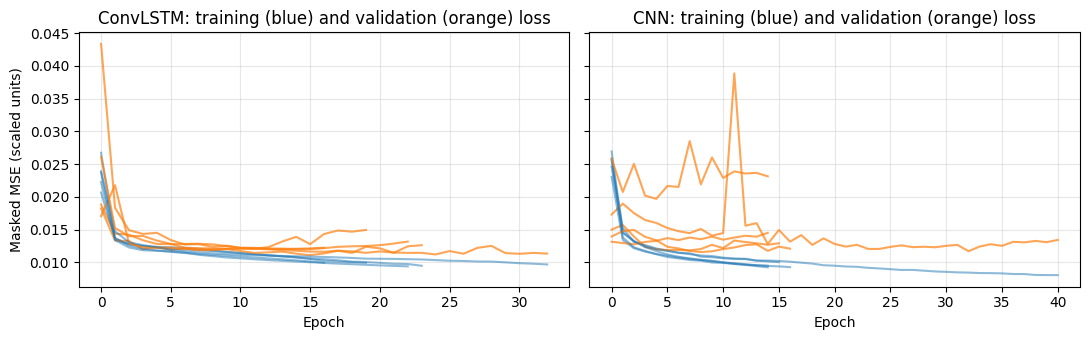

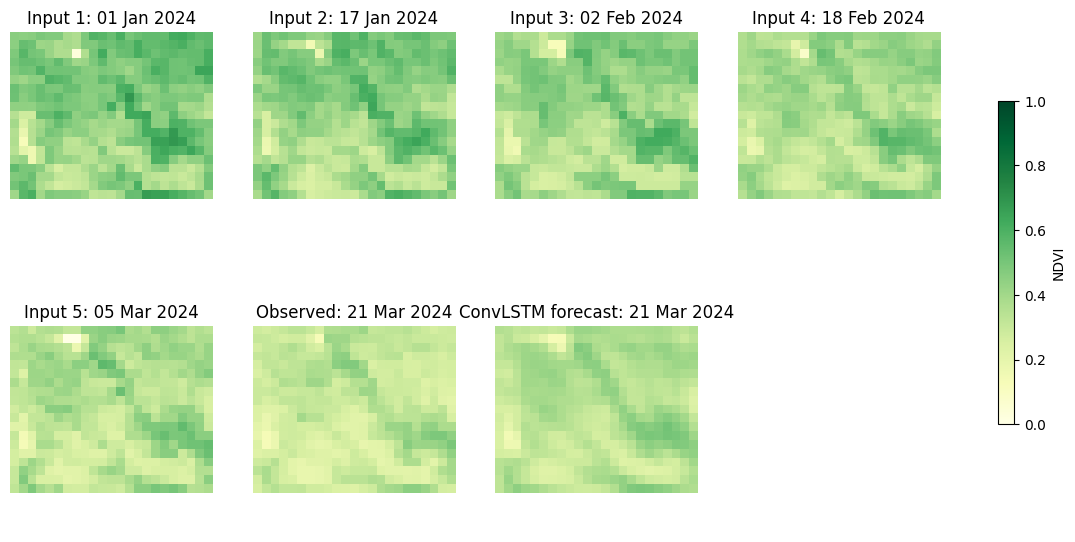

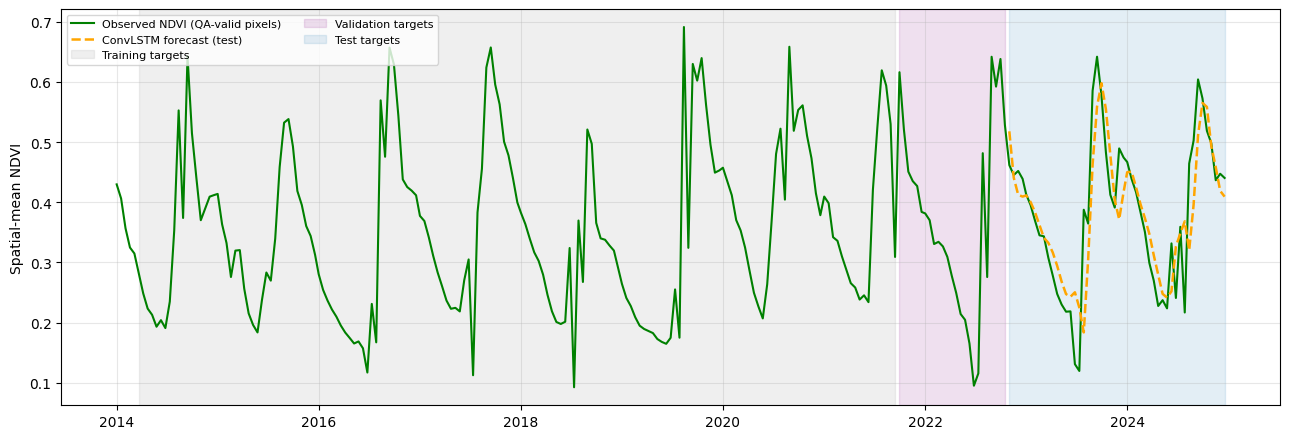

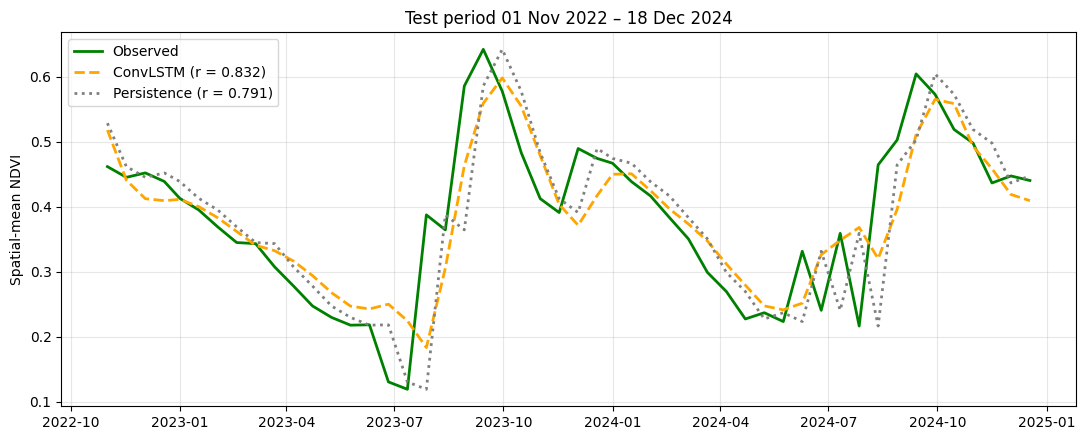

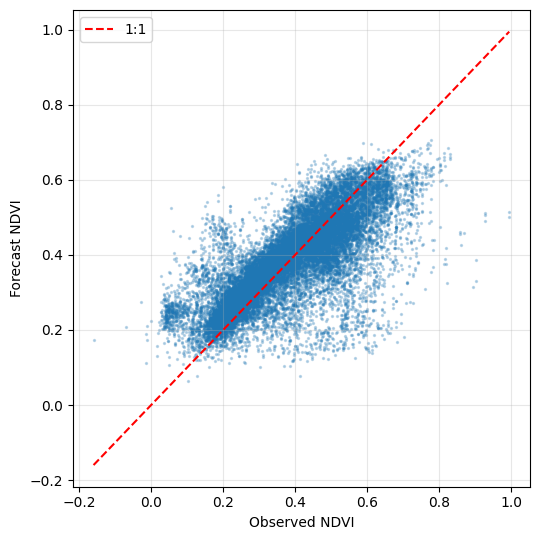

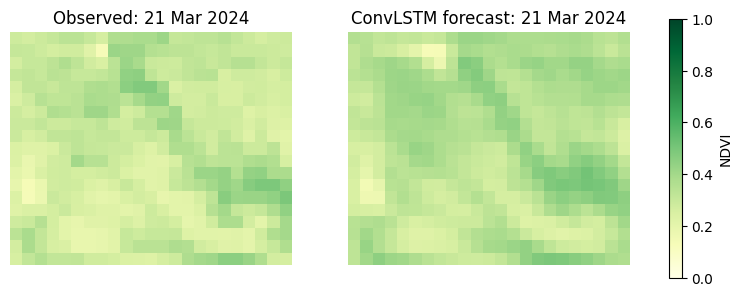

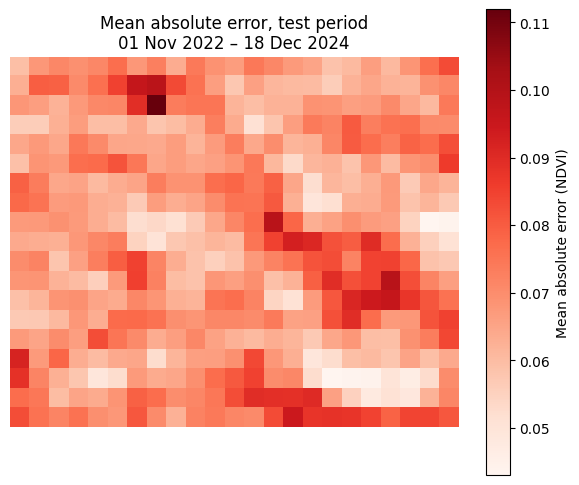

Max of per-pixel MAE: 0.1119


In [12]:
conv_mean = np.mean([r_['pred'] for r_ in runs['ConvLSTM']], axis=0)   # seed-averaged ConvLSTM
CM = 'YlGn'
fmt = lambda d: pd.Timestamp(d).strftime('%d %b %Y')

# training curves
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for a, name in zip(ax, ['ConvLSTM', 'CNN']):
    for r_ in runs[name]:
        a.plot(r_['history']['loss'], color='tab:blue', alpha=.5)
        a.plot(r_['history']['val_loss'], color='tab:orange', alpha=.7)
    a.set_title(f'{name}: training (blue) and validation (orange) loss'); a.set_xlabel('Epoch'); a.grid(alpha=.3)
ax[0].set_ylabel('Masked MSE (scaled units)')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig_training_curves.png', dpi=300); plt.show()

# Fig. 4 – five input composites, observed and predicted target
ex = int(np.where(tdates == pd.Timestamp(EXAMPLE_TARGET_DATE))[0][0]) if (tdates == pd.Timestamp(EXAMPLE_TARGET_DATE)).any() else int(te[len(te)//2])
assert ex in te, 'EXAMPLE_TARGET_DATE must be a test date'
fig, axs = plt.subplots(2, 4, figsize=(15, 7))
for k in range(L):
    fi = target_idx[ex] - L + k
    a = axs.flat[k]; im = a.imshow(raw[fi], cmap=CM, vmin=0, vmax=1); a.set_title(f'Input {k+1}: {fmt(dates[fi])}'); a.axis('off')
a = axs.flat[5]; a.imshow(Y_ndvi[ex], cmap=CM, vmin=0, vmax=1); a.set_title(f'Observed: {fmt(tdates[ex])}'); a.axis('off')
a = axs.flat[6]; a.imshow(conv_mean[ex], cmap=CM, vmin=0, vmax=1); a.set_title(f'ConvLSTM forecast: {fmt(tdates[ex])}'); a.axis('off')
axs.flat[7].axis('off')
fig.colorbar(im, ax=axs, shrink=.6, label='NDVI')
plt.savefig(f'{OUT_DIR}/fig4_sequence_example.png', dpi=300, bbox_inches='tight'); plt.show()

# Fig. 5 – full spatial-mean series with train / validation / test periods
obs_all = np.array([np.nanmean(raw[f]) for f in range(T)])
plt.figure(figsize=(13, 4.5))
plt.plot(dates, obs_all, color='green', lw=1.5, label='Observed NDVI (QA-valid pixels)')
plt.plot(tdates[te], spatial_mean_series(conv_mean[te], te), '--', color='orange', lw=1.8, label='ConvLSTM forecast (test)')
for idx, col, lab in [(tr, 'grey', 'Training targets'), (va, 'purple', 'Validation targets'), (te, 'tab:blue', 'Test targets')]:
    plt.axvspan(tdates[idx[0]], tdates[idx[-1]], color=col, alpha=.12, label=lab)
plt.ylabel('Spatial-mean NDVI'); plt.legend(loc='upper left', fontsize=8, ncol=2); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig5_mean_series.png', dpi=300); plt.show()

# Fig. 6 – test period: observed vs ConvLSTM vs persistence
obs_te = spatial_mean_series(Y_ndvi[te], te)
r_conv = baseline_table.set_index('Model').loc['ConvLSTM', 'r_spatial_mean']
r_pers = baseline_table.set_index('Model').loc['Persistence', 'r_spatial_mean']
plt.figure(figsize=(11, 4.5))
plt.plot(tdates[te], obs_te, color='green', lw=2, label='Observed')
plt.plot(tdates[te], spatial_mean_series(conv_mean[te], te), '--', color='orange', lw=2, label=f'ConvLSTM (r = {r_conv:.3f})')
plt.plot(tdates[te], spatial_mean_series(persistence[te], te), ':', color='grey', lw=2, label=f'Persistence (r = {r_pers:.3f})')
plt.ylabel('Spatial-mean NDVI'); plt.legend(); plt.grid(alpha=.3)
plt.title(f'Test period {fmt(tdates[te[0]])} – {fmt(tdates[te[-1]])}')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig6_test_series.png', dpi=300); plt.show()

# Fig. 7 – scatter of valid test pixels
o = Y_ndvi[te][EVAL_M[te]]; p = conv_mean[te][EVAL_M[te]]
plt.figure(figsize=(5.5, 5.5))
plt.scatter(o, p, s=2, alpha=.25)
lim = [min(o.min(), p.min()), max(o.max(), p.max())]
plt.plot(lim, lim, 'r--', label='1:1'); plt.xlabel('Observed NDVI'); plt.ylabel('Forecast NDVI'); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig7_scatter.png', dpi=300); plt.show()

# Fig. 8 – observed vs forecast for the example date
fig, axs = plt.subplots(1, 2, figsize=(10, 4.2))
for a, img, t in zip(axs, [Y_ndvi[ex], conv_mean[ex]], ['Observed', 'ConvLSTM forecast']):
    im = a.imshow(img, cmap=CM, vmin=0, vmax=1); a.set_title(f'{t}: {fmt(tdates[ex])}'); a.axis('off')
fig.colorbar(im, ax=axs, shrink=.8, label='NDVI')
plt.savefig(f'{OUT_DIR}/fig8_example_frame.png', dpi=300, bbox_inches='tight'); plt.show()

# Fig. 9 – mean absolute error over the whole test period
abs_err = np.where(EVAL_M[te], np.abs(conv_mean[te] - np.nan_to_num(Y_ndvi[te])), np.nan)
with np.errstate(all='ignore'):
    mae_map = np.nanmean(abs_err, axis=0)
plt.figure(figsize=(6, 5))
plt.imshow(mae_map, cmap='Reds'); plt.colorbar(label='Mean absolute error (NDVI)')
plt.title(f'Mean absolute error, test period\n{fmt(tdates[te[0]])} – {fmt(tdates[te[-1]])}'); plt.axis('off')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig9_mae_map.png', dpi=300); plt.show()
print('Max of per-pixel MAE:', round(float(np.nanmax(mae_map)), 4))

## 10. Text and tables for the manuscript (all numbers from this run)

In [13]:
bt = baseline_table.set_index('Model')
f4 = lambda x: f'{x:.4f}'
ci = lambda t: f'{t[0]:.4f} to {t[1]:.4f}'
c, pers = bt.loc['ConvLSTM'], bt.loc['Persistence']
ds = data_summary
lines = []
A = lines.append
A('# Results summary (paste into the manuscript)\n')
A(f'Run date: {dt.datetime.now():%Y-%m-%d %H:%M}; seeds {SEEDS}; TensorFlow {tf.__version__}; '
  f'Keras {keras.__version__}; Python {platform.python_version()}; GPU: {bool(tf.config.list_physical_devices("GPU"))}\n')
A('## Data (Table 1)')
A(f'- Time steps: {T} composites, {fmt(dates.iloc[0])} to {fmt(dates.iloc[-1])} '
  f'({ds["missing_composites_in_series"]} missing composites)')
A(f'- Spatial grid: {H} × {W} pixels, pixel size {ds["pixel_size_m"][0]} × {ds["pixel_size_m"][1]} m '
  f'({ds["extent_km"][0]} × {ds["extent_km"][1]} km), CRS {ds["crs"]}')
A(f'- QA-valid pixels overall: {100*ds["valid_pixel_fraction_overall"]:.1f} %\n')
A('## Split (Table 2)')
A(f'N = T − L = {T} − {L} = {N} windows.\n')
A('| Subset | Windows | Target dates |'); A('|---|---|---|')
for _, r_ in split.iterrows():
    A(f'| {r_.subset} | {r_.windows} | {fmt(r_.first_target)} to {fmt(r_.last_target)} |')
A('')
A(f'## Table 5. ConvLSTM scores (mean ± SD over {len(SEEDS)} seeds, NDVI units, QA-valid pixels)')
try:
    A(table5.to_markdown())
except ImportError:                       # 'tabulate' not installed
    A('| Metric | ' + ' | '.join(table5.columns) + ' |'); A('|---' * (len(table5.columns) + 1) + '|')
    for k, r_ in table5.iterrows(): A(f'| {k} | ' + ' | '.join(r_.values) + ' |')
A('')
A('## Table 6. Test-set comparison with reference forecasts')
A('| Model | RMSE | MAE | R² | SSIM | r (spatial mean) | Skill vs persistence | RMSE 95 % CI† | Skill 95 % CI† |')
A('|---|---|---|---|---|---|---|---|---|')
for name, r_ in bt.iterrows():
    sd = lambda k: f' ± {r_[k + "_sd"]:.4f}' if r_['runs'] > 1 else ''
    skill = '—' if name == 'Persistence' else f'{r_["Skill_vs_persistence"]:.3f}' + (f' ± {r_["Skill_sd"]:.3f}' if r_['runs'] > 1 else '')
    sci = '—' if name == 'Persistence' else ci(r_['Skill_CI95'])
    A(f'| {name} | {f4(r_.RMSE)}{sd("RMSE")} | {f4(r_.MAE)}{sd("MAE")} | {f4(r_.R2)}{sd("R2")} | '
      f'{f4(r_.SSIM)}{sd("SSIM")} | {r_.r_spatial_mean:.3f} | {skill} | {ci(r_.RMSE_CI95)} | {sci} |')
A('† Moving-block bootstrap of test dates (block = %d composites, %d resamples); for CNN and ConvLSTM the CI is for the seed-averaged forecast. ± values are SD over seeds.' % (BLOCK, N_BOOT))
A('')
better = c['RMSE_CI95'][1] < pers['RMSE'] or c['Skill_CI95'][0] > 0
A('## Abstract / results sentence')
A(f'On the held-out test set ({len(te)} composites, {fmt(tdates[te[0]])} – {fmt(tdates[te[-1]])}), the ConvLSTM '
  f'obtained RMSE = {c.RMSE:.3f} ± {c.RMSE_sd:.3f}, MAE = {c.MAE:.3f}, R² = {c.R2:.2f} and mean SSIM = {c.SSIM:.2f} '
  f'(mean ± SD over {len(SEEDS)} seeds), compared with RMSE = {pers.RMSE:.3f} for persistence, '
  f'{bt.loc["Seasonal naive"].RMSE:.3f} for the seasonal-naïve forecast, {bt.loc["Climatology"].RMSE:.3f} for climatology '
  f'and {bt.loc["CNN"].RMSE:.3f} for the CNN. The skill relative to persistence was '
  f'{c.Skill_vs_persistence:.2f} (95 % CI {ci(c.Skill_CI95)}).')
A('')
A('**Interpretation check:** ' + ('the skill CI is above zero, so the ConvLSTM beats persistence on this test set.'
   if c['Skill_CI95'][0] > 0 else
   'the skill CI includes zero (or is negative): do NOT claim the ConvLSTM outperforms persistence.'))
beaten_by = [n for n in ['Seasonal naive', 'Climatology', 'CNN'] if bt.loc[n].RMSE < c.RMSE]
A('**Other baselines:** ' + ('the ConvLSTM has the lowest RMSE of all models.' if not beaten_by else
  'these models have LOWER test RMSE than the ConvLSTM: ' + ', '.join(beaten_by) +
  '. Report this honestly; do not describe the ConvLSTM as the best model.'))
open(f'{OUT_DIR}/results_summary.md', 'w').write('\n'.join(lines))
print('\n'.join(lines))

# Results summary (paste into the manuscript)

Run date: 2026-11-24 06:39; seeds [0, 1, 2, 3, 4]; TensorFlow 2.21.0; Keras 3.13.2; Python 3.13.16; GPU: True

## Data (Table 1)
- Time steps: 253 composites, 01 Jan 2014 to 18 Dec 2024 (0 missing composites)
- Spatial grid: 19 × 23 pixels, pixel size 250.0 × 250.0 m (5.75 × 4.75 km), CRS PROJCS["MODIS Sinusoidal",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Sinusoidal"],PARAMETER["longitude_of_center",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
- QA-valid pixels overall: 100.0 %

## Split (Table 2)
N = T − L = 253 − 5 = 248 windows.

| Subset | Windows | Target dates |
|---|---|---|
| Training | 173 | 22 Mar 2014 to 14 Sep 2021 |
| Validation | 25 | 30 Sep 2021 to 1

## 11. Save provenance and package the results

In [14]:
run_info = {
    'run_finished': dt.datetime.now().isoformat(timespec='seconds'),
    'python': platform.python_version(), 'tensorflow': tf.__version__, 'keras': keras.__version__,
    'numpy': np.__version__, 'pandas': pd.__version__, 'scikit_image': skimage.__version__,
    'scipy': scipy.__version__, 'rasterio': rasterio.__version__, 'matplotlib': matplotlib.__version__,
    'devices': [d.name for d in tf.config.list_physical_devices()],
    'config': dict(SEQ_LEN=SEQ_LEN, TEST_FRAC=TEST_FRAC, VAL_FRAC=VAL_FRAC, SEEDS=SEEDS, MAX_EPOCHS=MAX_EPOCHS,
                   PATIENCE=PATIENCE, MIN_EPOCHS=MIN_EPOCHS, BN_MOMENTUM=BN_MOMENTUM, BATCH=BATCH, LR=LR, N_BOOT=N_BOOT, BLOCK=BLOCK),
    'scaling_min_max_ndvi': [vmin, vmax],
    'best_epochs': {k: [r_['best_epoch'] for r_ in v] for k, v in runs.items()},
    'parameters': {k: v[0]['params'] for k, v in runs.items()},
}
json.dump(run_info, open(f'{OUT_DIR}/run_info.json', 'w'), indent=2)
np.savez_compressed(f'{OUT_DIR}/predictions_test.npz', dates=tdates[te].astype(str).values,
                    observed=Y_ndvi[te], convlstm_seed_mean=conv_mean[te], persistence=persistence[te])
import shutil; shutil.make_archive('results', 'zip', OUT_DIR)
print(json.dumps(run_info, indent=2)); print('Saved results.zip')

{
  "run_finished": "2026-11-24T06:39:11",
  "python": "3.13.16",
  "tensorflow": "2.21.0",
  "keras": "3.13.2",
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "scikit_image": "0.25.2",
  "scipy": "1.16.3",
  "rasterio": "1.5.2",
  "matplotlib": "3.10.0",
  "devices": [
    "/physical_device:CPU:0",
    "/physical_device:GPU:0"
  ],
  "config": {
    "SEQ_LEN": 5,
    "TEST_FRAC": 0.2,
    "VAL_FRAC": 0.1,
    "SEEDS": [
      0,
      1,
      2,
      3,
      4
    ],
    "MAX_EPOCHS": 50,
    "PATIENCE": 8,
    "MIN_EPOCHS": 5,
    "BN_MOMENTUM": 0.9,
    "BATCH": 4,
    "LR": 0.001,
    "N_BOOT": 1000,
    "BLOCK": 4
  },
  "scaling_min_max_ndvi": [
    -0.1842,
    0.9985
  ],
  "best_epochs": {
    "ConvLSTM": [
      12,
      16,
      9,
      25,
      15
    ],
    "CNN": [
      8,
      33,
      3,
      9,
      5
    ]
  },
  "parameters": {
    "ConvLSTM": 261409,
    "CNN": 22081
  }
}
Saved results.zip
